# RiMEA 12d: Bottleneck Width and Flow

This notebook demonstrates the current public implementation of RiMEA Test 12d. We load one base bottleneck scenario, vary the bottleneck width, run the simulation for each width, and compute the flow as the number of agents divided by the evacuation time of the run, the same measure as the automated test `TestRiMEA12d`.

Widths used in this notebook:

- `0.8 m`
- `1.0 m`
- `1.2 m`

The final plot shows this flow $J$ against the bottleneck width $w$. The evacuation time includes the walk to the bottleneck and on to the goal, so $J$ is a run-level flow, not a flow measured at the bottleneck. The comparison uses one run per width.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 16 October 2026, 12:38 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pedpy

from jupedsim_scenarios import load_scenario, run_scenario


In [3]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#f7f7f5",
        "axes.edgecolor": "#3a3a3a",
        "axes.labelcolor": "#1d1d1d",
        "axes.titleweight": "bold",
        "xtick.color": "#1d1d1d",
        "ytick.color": "#1d1d1d",
        "font.size": 11,
    }
)

SCENARIO_DIR = Path("scenario_files") / "Rimea-12d-bottleneck.zip"
WIDTHS = [0.8, 1.0, 1.2]


## Load the Base Scenario

The scenario directory contains the shared distribution, exit, and route. The base geometry uses a `1.0 m` bottleneck, and the notebook clones it in memory for the other widths.

In [4]:
base_scenario = load_scenario(str(SCENARIO_DIR))
print(base_scenario.summary())

Scenario: standards/rimea/scenario_files/Rimea-12d-bottleneck.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      600s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~50
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 50 agents


## Helper Functions

We deep-copy the loaded raw scenario before creating each width variant. This keeps nested configuration changes isolated, so one run cannot accidentally mutate the next one.

The flow of a run is `agents_evacuated / evacuation_time`, in agents per second, as in the test. The measurement line is used only to draw the bottleneck in the geometry plots.

In [5]:
def make_geometry(width: float) -> str:
    half_width = width / 2.0
    center_y = 5.0
    return (
        f"POLYGON ((0 0, 10 0, 10 {center_y - half_width}, 15 {center_y - half_width}, "
        f"15 0, 25 0, 25 10, 15 10, 15 {center_y + half_width}, "
        f"10 {center_y + half_width}, 10 10, 0 10, 0 0))"
    )


def measurement_line(width: float) -> pedpy.MeasurementLine:
    half_width = width / 2.0
    center_y = 5.0
    measurement_line_x = 10
    return pedpy.MeasurementLine(
        [(measurement_line_x, center_y - half_width), (measurement_line_x, center_y + half_width)]
    )


def run_width_variant(base, width: float) -> dict:
    variant = base.copy()
    variant.source_path = f"rimea-12d-bottleneck-w{width:.1f}"
    variant.walkable_area_wkt = make_geometry(width)
    result = run_scenario(variant, seed=42)
    traj = pedpy.TrajectoryData(
        result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy(),
        frame_rate=result.frame_rate,
    )
    line = measurement_line(width)
    metrics = dict(result.metrics)
    result.cleanup()
    flow = metrics["agents_evacuated"] / metrics["evacuation_time"]
    return {
        "width": float(width),
        "scenario": variant,
        "line": line,
        "walkable_area": pedpy.WalkableArea(variant.walkable_polygon),
        "trajectory": traj,
        "flow": float(flow),
        "metrics": metrics,
    }


## Run the Width Sweep

In [6]:
%%capture
runs = [run_width_variant(base_scenario, width) for width in WIDTHS]
summary_rows = [
    {
        "width_m": run["width"],
        "flow_agents_per_s": round(run["flow"], 3),
        "evacuation_time_s": round(run["metrics"]["evacuation_time"], 2),
        "agents_evacuated": run["metrics"]["agents_evacuated"],
    }
    for run in runs
]
summary_rows

## Plot Geometries and Trajectories

Before comparing the flow values, we can inspect the three bottleneck widths directly. Each panel shows the room geometry, the bottleneck measurement line, and the simulated trajectories for that width.

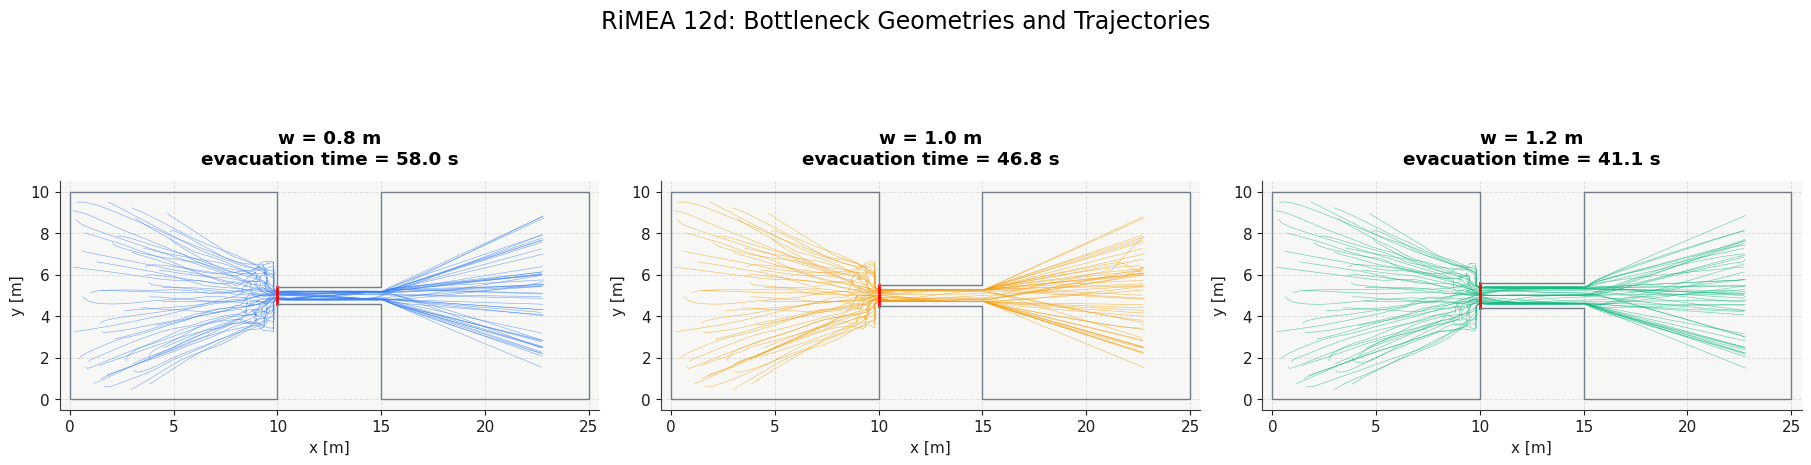

In [7]:
TRAJECTORY_COLORS = {
    0.8: "#3B82F6",
    1.0: "#F59E0B",
    1.2: "#10B981",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

for ax, run in zip(axes, runs):
    color = TRAJECTORY_COLORS[run["width"]]
    pedpy.plot_measurement_setup(
        traj=run["trajectory"],
        walkable_area=run["walkable_area"],
        measurement_lines=[run["line"]],
        axes=ax,
        traj_alpha=0.7,
        traj_width=0.4,
        ml_width=2,
        ml_alpha=0.2,
        traj_color=color,
        ml_color="red",
    ).set_aspect("equal")
    ax.set_title(
        f"w = {run['width']:.1f} m\n"
        f"evacuation time = {run['metrics']['evacuation_time']:.1f} s",
        pad=12,
    )
    ax.set_xlim(-0.5, 25.5)
    ax.set_ylim(-0.5, 10.5)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("RiMEA 12d: Bottleneck Geometries and Trajectories", fontsize=17, y=1.02)
plt.show()

## Plot Flow Against Bottleneck Width

The colored line shows the flow, agents evacuated divided by evacuation time, for each simulated width. The flows are printed below the plot.

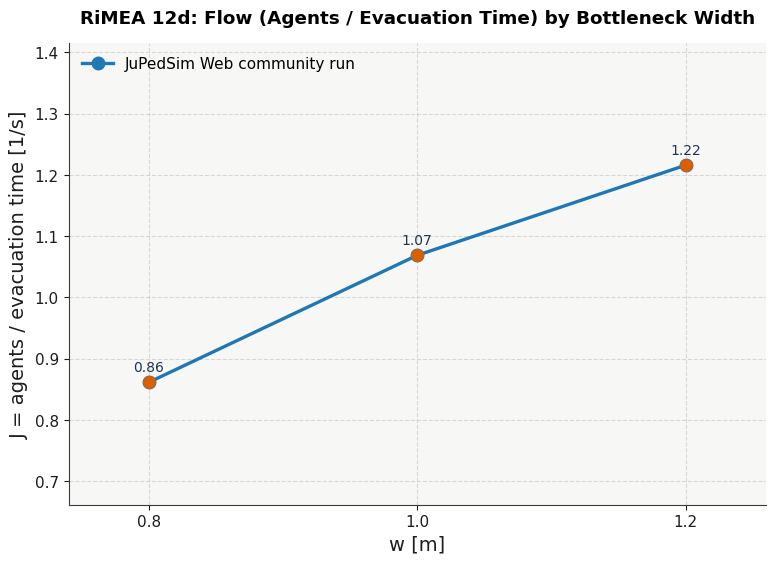

w = 0.8 m: flow = 0.861 agents/s, evacuation time = 58.05 s, agents evacuated = 50
w = 1.0 m: flow = 1.069 agents/s, evacuation time = 46.79 s, agents evacuated = 50
w = 1.2 m: flow = 1.216 agents/s, evacuation time = 41.13 s, agents evacuated = 50


In [8]:
widths = np.array([run["width"] for run in runs], dtype=float)
flows = np.array([run["flow"] for run in runs], dtype=float)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(
    widths,
    flows,
    color="#1f77b4",
    linewidth=2.4,
    marker="o",
    markersize=9,
    label="JuPedSim Web community run",
)
ax.scatter(widths, flows, color="#d95f02", s=70, zorder=3)

for width, flow in zip(widths, flows):
    ax.annotate(
        f"{flow:.2f}",
        (width, flow),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        color="#1d3557",
        fontsize=10,
    )

ax.set_title("RiMEA 12d: Flow (Agents / Evacuation Time) by Bottleneck Width", pad=14)
ax.set_xlabel("w [m]", fontsize=14)
ax.set_ylabel("J = agents / evacuation time [1/s]", fontsize=14)
ax.set_xticks(widths)
ax.set_xlim(0.74, 1.26)
ax.set_ylim(flows.min() - 0.2, flows.max() + 0.2)
ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

for run in runs:
    print(
        f"w = {run['width']:.1f} m: flow = {run['flow']:.3f} agents/s, "
        f"evacuation time = {run['metrics']['evacuation_time']:.2f} s, "
        f"agents evacuated = {run['metrics']['agents_evacuated']}"
    )
